# Multispectral Remote Sensing

Now that we have wrangled our Landsat data, we can begin to explore how to use the unique properties of multispectral data to infer information about properties of the Earth surface.

We will continue to use the dataset we produced in the previous notebook, which should be called `LC08_L2SP_042034_20260609_20260613_02_T1_SR.tif` and saved in the same directory as this notebook.

In [1]:
import xarray as xr
import rioxarray as rxr

import matplotlib.pyplot as plt

## Re-loading the data

Let's load the data again:

In [7]:
scene = rxr.open_rasterio("LC08_L2SP_042034_20260609_20260613_02_T1_SR.tif")  # open the Landsat 8 surface reflectance GeoTIFF file as a masked xarray DataArray

scene

<xarray.DataArray (band: 7, y: 1234, x: 1668)> Size: 58MB
[14408184 values with dtype=float32]
Coordinates:
  * band         (band) int64 56B 1 2 3 4 5 6 7
  * y            (y) float64 10kB 4.167e+06 4.167e+06 ... 4.13e+06 4.13e+06
  * x            (x) float64 13kB 3.37e+05 3.37e+05 ... 3.87e+05 3.87e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point
    _FillValue:     0.0
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('aerosol', 'blue', 'green', 'red', 'nir', 'swir1', 'swir2')

Annoyingly, our nicely named `band` coordinate seems to have reverted to simply a list of integers. This is because GeoTiff file metadata doesn't have a concept of `string`-based band names in the same way that `xarray` can manage. Luckily, we also saved our band names as the `long_name` attribute, so we can fix this:

In [14]:
scene['band'] = list(scene.attrs['long_name'])  # assign the band names to the 'band' coordinate of the DataArray

scene

<xarray.DataArray (band: 7, y: 1234, x: 1668)> Size: 58MB
[14408184 values with dtype=float32]
Coordinates:
  * band         (band) <U7 196B 'aerosol' 'blue' 'green' ... 'swir1' 'swir2'
  * y            (y) float64 10kB 4.167e+06 4.167e+06 ... 4.13e+06 4.13e+06
  * x            (x) float64 13kB 3.37e+05 3.37e+05 ... 3.87e+05 3.87e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point
    _FillValue:     0.0
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('aerosol', 'blue', 'green', 'red', 'nir', 'swir1', 'swir2')

Now we can plot our data as usual:

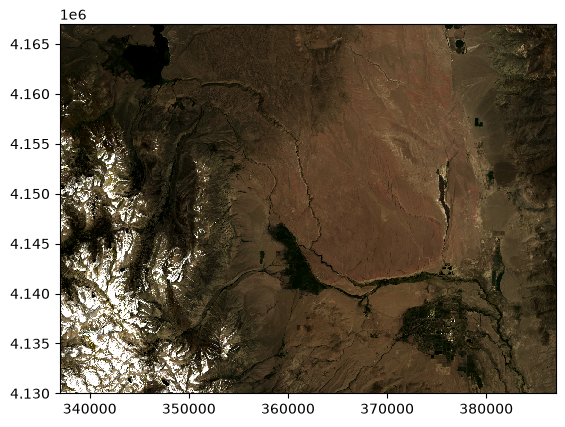

In [95]:
rgb = scene.sel(band=["red", "green", "blue"])  # select the red, green, and blue bands in order

# plot the RGB image using a robust stretch to enhance contrast and remove axis labels
rgb.plot.imshow(robust=True, add_labels=False)  

## Examining the multispectral bands

With some `matplotlib` wrangling, we can visualise each band individually:

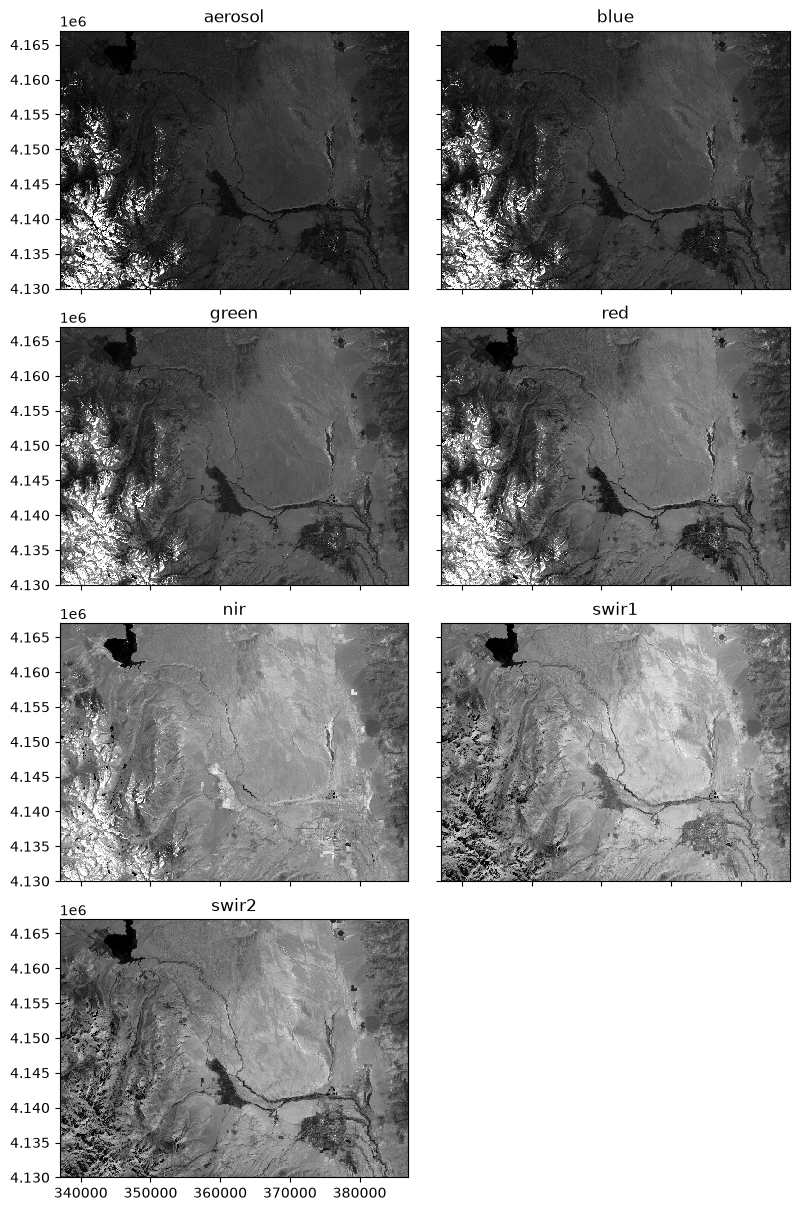

In [97]:
# plot all seven bands in a single figure, using a 2x4 grid of subplots
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(8, 12), sharex=True, sharey=True, layout='constrained')  # create a 2x4 grid of subplots

for i, ax in enumerate(axes.flat):  # flatten the 2D array of axes for easy iteration

    if i < len(scene.band):  # check if the current index is less than the number of bands
        scene_band = scene.isel(band=i)  # select the current band
        scene_band.plot.imshow(ax=ax, cmap='Greys_r', vmin=0, vmax=0.6, add_colorbar=False, add_labels=False)  # plot the band on the current axis
        ax.set_title(scene_band.band.values)  # set the title of the subplot to the band name
        # ax.set_xlabel("")  # remove the x-axis label for a cleaner look
        # ax.set_ylabel("")  # and the y-axis label
        ax.set_aspect('equal')  # set the aspect ratio to 1:1, so that the image is not 'stretched' in one direction

    else:
        ax.axis('off')  # for the final subplot (which has no corresponding band), turn off the axis

Take some time to examine some of the bright/dark features in the image, and see how the radiometric coverage of the band (available in the table of the previous section) relate to the actual surface features you can observe in the [Google Maps data of the region](https://www.google.com/maps/@37.489024,-118.5713044,46092m/data=!3m1!1e3!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D). 

You might notice some features such as the following:

 - Snow appears very 'bright' (high reflectivity) in most bands, but very 'dark' (low reflectivity) in the short-wave infra-red bands.
 - Fields and vegetation appear dark in most bands but bright in near infra-red.
 - Water appears dark in all bands.

These differences in spectral behaviours form the foundation of the sort of analysis we can perform with multispectral data.


## False-colour composite imagery

A qualitative way we can take advantage of these difference in reflectivity across the spectrum is by producing false-colour imagery. Up until now, our colour imagery plots have been provided with the 'correct' bands (i.e. red, green, and blue in order). However, we can provide 'incorrect' values that highlight different properties of the surface.

A classic example of false-colour satellite imagery is the colour infrared composite: here, we provide NIR (Band 5) to the red channel, red (Band 4) to the green channel, and green (band 3) to the blue channel:

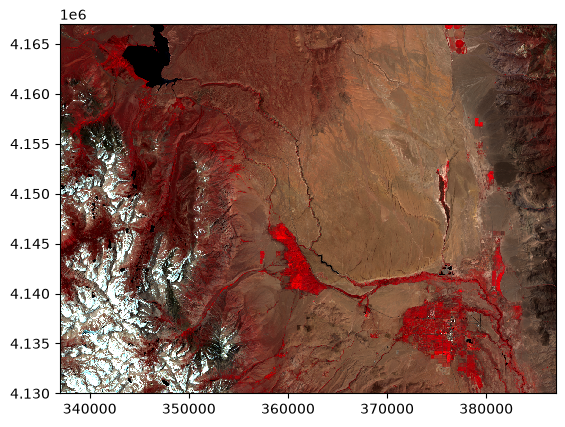

In [98]:
false_veg = scene.sel(band=["nir", "red", "green"])  # select the NIR, red, and green bands in order

false_veg.plot.imshow(robust=True, add_labels=False)  # plot the false vegetation image using a robust stretch to enhance contrast

This visualisation acts to highlight vegetation: healthy green vegetation strongly reflects NIR light, making it appear as a bright red in the false-colour image. Water bodies absorb NIR light, making them appear dark. Note how much easier it is to contrast the vegetation around the boundary of the lake to the northwest of this image compared to the original 'true-colour' RGB image.

Another commonly used composite highlights snow in bright blue and vegetation in bright green;

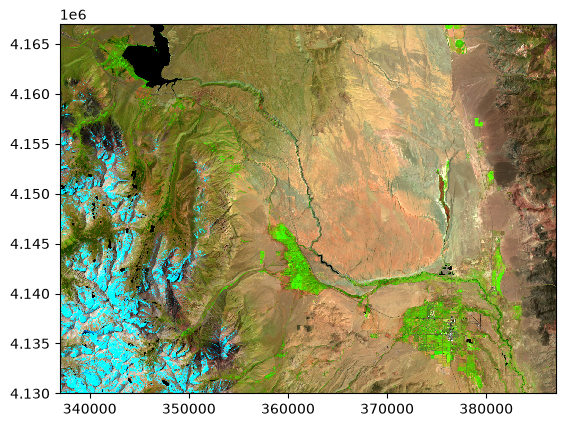

In [99]:
false_snow = scene.sel(band=["swir1", "nir", "red"])  # select the SWIR2, NIR, and blue bands in order

false_snow.plot.imshow(robust=True, add_labels=False)  # plot the false snow image using a robust stretch to enhance contrast

There are many band combinations that [you can find online](https://www.esri.com/arcgis-blog/products/product/imagery/band-combinations-for-landsat-8), so you may be able to find a qualitative combination that acts ot highlight whatever surface change you like (so long as it detectable in the wavelengths you have to hand!).

## Spectral indices

Multispectral approaches to satellite remote sensing use these reflectance differences to extract quantiative information about the Earth surface. There is a range of complexity with which you can approach this task: for the purposes of this unit, we will focus on perhaps the most simple, which uses simple band algebra (i.e. simple algorithms applied to combinations of bands). However, the Python ecosystem can provide the interested end-user with the tools to perform a wealth of more complicated analysis, such as unsupervised (e.g. K-Means of ISODATA) or supervised (MLC or Random Forest) classification through to more advanced deep learning methods (e.g. U-Nets or vision transformer approaches).

Our band algebra approaches will all fall under the broad umbrella of **spectral indices**, which combine two or more spectral bands to highlight a specific surface type such as vegetation, water, urban areas, or snow. A specific subset are referred to as **normalised difference indices (NDI)**, which follow a specific formula in the form:

$$NDI = \frac{r_{high} - r_{low}}{r_{high} + r_{low}}$$

Where $r_{high}$ is a band that has characteristically high reflectance for our surface of interest, and $r_{low}$ has characteristically low reflectance. The difference of these two bands is divided by their sum, producing an output that is mathematically bounded between -1 and +1.

From this principle, there are a number of useful normalised difference indices we can use (and more I'm sure you can find):

| Name | Equation |
| ---- | -------- |
| Normalised Difference Vegetation Index | $$NDVI = \frac{NIR_{B5} - Red_{B4}}{NIR_{B5} + Red_{B4}}$$ |
| Normalised Difference Snow Index | $$NDSI = \frac{Green_{B3} - SWIR1_{B6}}{Green_{B3} + SWIR1_{B6}}$$ |
| Normalised Difference Water Index | $$NDWI = \frac{Green_{B3} - NIR_{B5}}{Green_{B3} + NIR_{B5}}$$ |
| Normalised Difference Built-up Index | $$NDBI = \frac{SWIR_{B6} - NIR_{B5}}{SWIR_{B6} + NIR_{B5}}$$ |
| Normalised Difference Water Index (over ice) | $$NDWI_{ice} = \frac{Blue_{B2} - Red_{B4}}{ Blue_{B2} + Red_{B4}}$$ |
| Normalised Burn Ratio | $$NBR = \frac{NIR_{B5} - SWIR2_{B7}}{NIR_{B5} + SWIR2_{B7}}$$ |

I have included the relevant Landsat 8/9 bands as subscript in the equations - note this won't be the same if you start using different sensors (e.g., Landsat 1-7 or Sentinel-2) in the future.

## Putting normalised difference indices into practice

Let's construct the NDVI as an example:

In [89]:
# replace negative values with 0. These can occur due to atmospheric correction but disrupt the NDVI calculation
scene_flt = scene.where(scene >= 0, 0)  

# Calculate NDVI using the NIR and red bands
ndvi = (
    scene_flt.sel(band="nir") - scene_flt.sel(band="red")) / (scene_flt.sel(band="nir") + scene_flt.sel(band="red")
    )

# set the long_name attribute of the NDVI DataArray
ndvi.attrs['long_name'] = "Normalised Difference Vegetation Index"  

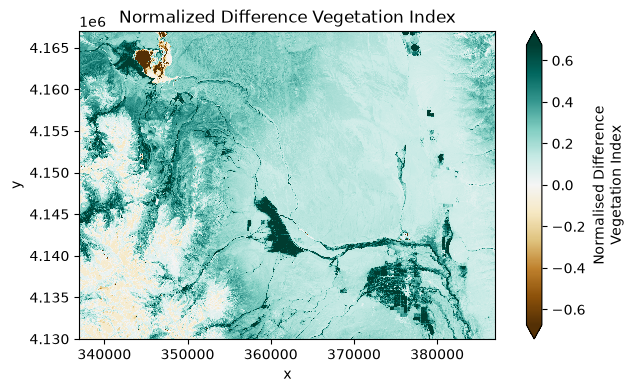

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

# plot the NDVI image using a diverging colormap and a robust stretch to enhance contrast
ndvi.plot.imshow(ax=ax, cmap='BrBG', robust=True)  

ax.set_title("Normalized Difference Vegetation Index")
ax.set_aspect('equal')

We can now see a clear pattern: regions more likely to be vegetation have values increasingly greater than 0, and regions less likely to be vegetation have values increasingly less then 0.

There are two methods we can use to try and extract quantitative information from an image.

 - The first is to use a given threshold to define what is and isn't vegetation.
 - The second is to track the change in some sort of aggregate value (mean, median, etc.) of a define area over time (we will do this in our next session).

However, choosing what a threshold will have some aspect of subjectivity. We can use a histogram to begin to give us some idea of a useful boundary:

[]

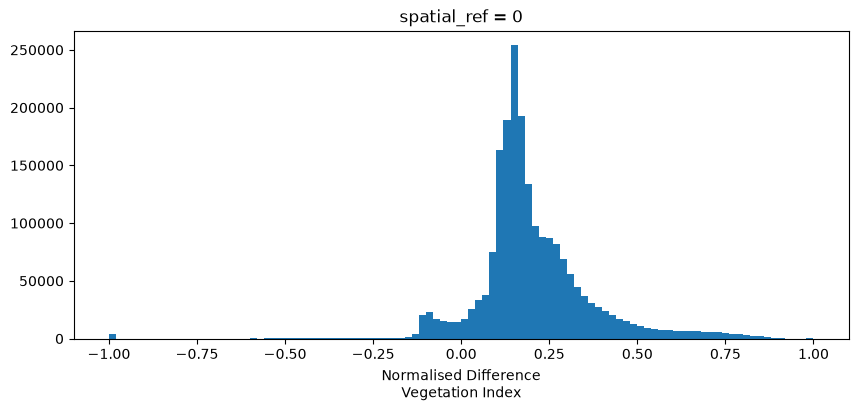

In [91]:
ndvi.plot.hist(bins=100, figsize=(10, 4)) 
plt.plot()

Ideally, what we want to see is a nice bimodal distribution between 'vegetation' and 'not vegetation'. If this was the case, we could just pick the lowest value between the two peaks as a useful boundary threshold value. Clearly, that isn't the case here. There appears to be a number of steps in behaviour, from a low value at approximately 0 to an unusual flattening between 0.2 and 0.25 and between 0.5 and 0.7.

We could use this to inform some thresholds and test their behaviour:

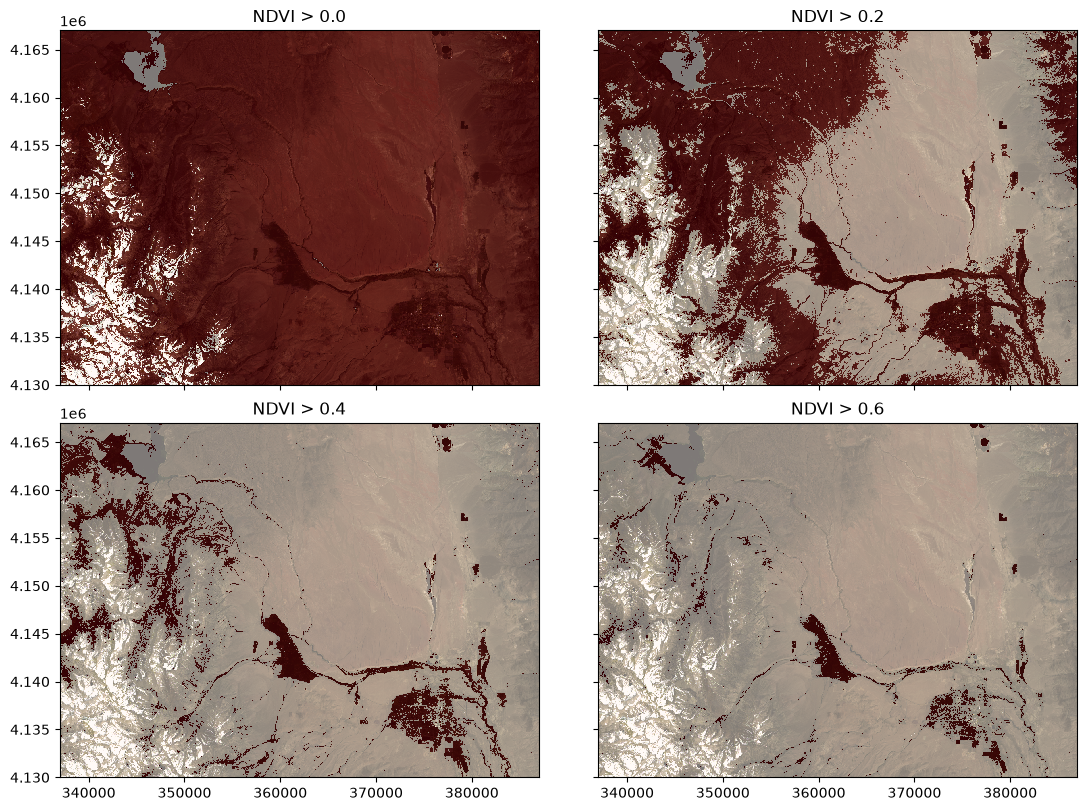

In [ ]:
# construct masks at values of 0.0, 0.2, 0.4, and 0.6
veg_mask_00 = ndvi > 0.0
veg_mask_02 = ndvi > 0.2
veg_mask_04 = ndvi > 0.4
veg_mask_06 = ndvi > 0.6

fig, axes = plt.subplots(ncols=2, nrows=2, sharex=True, sharey=True, figsize=(11, 8), layout='constrained')  # create a new figure and axis for plotting

for ax, mask, threshold in zip(axes.flat, [veg_mask_00, veg_mask_02, veg_mask_04, veg_mask_06], [0.0, 0.2, 0.4, 0.6]):  # iterate over the axes and masks

    rgb.plot.imshow(ax=ax, robust=True, add_labels=False)  # plot the RGB image on the current axis
    mask.plot.imshow(ax=ax, cmap='Reds', alpha=0.5, add_colorbar=False, add_labels=False)  # plot the mask on the current axis, with a red colormap and 50% transparency
    ax.set_title(f"NDVI > {threshold}")  # set the title of the subplot to indicate the threshold
    ax.set_aspect('equal')  # set the aspect ratio to 1:1, so that the image is not 'stretched' in one direction

You can compare these masks to the [Google Maps data of the region](https://www.google.com/maps/@37.489024,-118.5713044,46092m/data=!3m1!1e3!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D) to infer what these thresholds in the histogram begin to identify. Using Streetview to get an up-close view of the surface is particularly useful.

 - A threshold of 0 excludes onlt snow and ice: all other surface are retained.
 - Increasing the threshold to 0.2 filters out the most arid parts of the zone. On Streetview, these filtered regions look to be largely [desert shrubland](https://www.google.com/maps/@37.4545335,-118.5608307,1481a,60y,291.61h,79.12t/data=!3m7!1e1!3m5!1szxq2FjGYuVnE7YYSXbd_jw!2e0!6shttps:%2F%2Fstreetviewpixels-pa.clients6.google.com%2Fv1%2Fthumbnail%3Fcb_client%3Dmaps_sv.tactile%26w%3D900%26h%3D600%26pitch%3D10.884215268001995%26panoid%3Dzxq2FjGYuVnE7YYSXbd_jw%26yaw%3D291.61268574338266!7i16384!8i8192!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D). However, large regions with with [sparse woodland](https://www.google.com/maps/@37.524454,-118.6206008,2025a,90y,67.55h,79.27t/data=!3m7!1e1!3m5!1s65KMbuRyUu37Gnxsv6dgJA!2e0!6shttps:%2F%2Fstreetviewpixels-pa.clients6.google.com%2Fv1%2Fthumbnail%3Fcb_client%3Dmaps_sv.tactile%26w%3D900%26h%3D600%26pitch%3D10.728715270798943%26panoid%3D65KMbuRyUu37Gnxsv6dgJA%26yaw%3D67.54561236912083!7i16384!8i8192!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D) are retained.
 - Increasing the threshold to 0.4 filters out the sparse woodland, but keeps [denser woodland](https://www.google.com/maps/@37.5593299,-118.6996307,2135a,84.9y,141.96h,99.67t/data=!3m7!1e1!3m5!1slLxfvCO2S6W0nb-zY_ap_g!2e0!6shttps:%2F%2Fstreetviewpixels-pa.clients6.google.com%2Fv1%2Fthumbnail%3Fcb_client%3Dmaps_sv.tactile%26w%3D900%26h%3D600%26pitch%3D-9.665971741425409%26panoid%3DlLxfvCO2S6W0nb-zY_ap_g%26yaw%3D141.9598474308261!7i16384!8i8192!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D) in the foothills of the mountains.
 - An NDVI threshold of 0.6 filters out all but the healthiest vegetation, largely [actively maintained crops and farmland](https://www.google.com/maps/@37.41954,-118.5736322,1392a,75y,34.82h,89.5t/data=!3m8!1e1!3m6!1sCIHM0ogKEICAgIDZgtvAfQ!2e10!3e11!6shttps:%2F%2Flh3.googleusercontent.com%2Fgpms-cs-s%2FAM4Q-U-KTcyXWsaRKxkGfpazZcNFlWzbABnAExjpEnJNoT_DBiHpuj4CnLywvEpXPgTCJbqlmTvrL_nUrsO9JOIEMIWHFanxk6Rot5nuGDnC3TQw2hrr6m4KnJrWYHmTz-JWGWZK29HS%3Dw900-h600-k-no-pi0.4952286795130618-ya40.57568075074926-ro0-fo100!7i5760!8i2880!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D).

It's clear that, as a mix of vegetation and bare soil can exist within the 30 x 30 m grid of any Landsat pixel, we are not dealing with any single strict cutoff. We have to make a decision about what is most suitable for our use case, research question, dataset, and method. 

Note there is an automated approach to determining a simple bimodal threshold, called Otsu's method. I [outline how you can use this in one of the optional recipes](../../recipes/otsu-threshold.ipynb). However, I hope this example shows that determining a threshold isn't always a simple, clear-cut decision.

## Acknowledging and quantifying uncertainty

Let's say that, for our purposes, a **threshold of 0.4** might be the most useful. For science purposes, we still might want to deliver any quantiative values we provide with a level of uncertainty associated with any primary result. 

A useful way to do this for NDI values is to perform a simple **sensitivity analysis**. This shows how much our final values might change depending on our input threshold.

Below, we explore a sensitivity threshold of 0.05 around a central value of 0.4. We calculate the total area classified as vegetation for each of the three possible thresholds (0.35, 0.4, and 0.45).

In [88]:
# Use an NDVI of 0.4 to calculate the area of vegetation in the scene.
# Perform a sensitivity analysis of +/- 0.05

ndvi_threshold = 0.4  # set the NDVI threshold for vegetation
sensitivity = 0.05  # set the sensitivity for the analysis

# create a mask for vegetation based on the NDVI threshold
ndvi_mask = ndvi > ndvi_threshold 
ndvi_mask_sensitivity_plus = ndvi > (ndvi_threshold + sensitivity)
ndvi_mask_sensitivity_minus = ndvi > (ndvi_threshold - sensitivity)

 # area of a single pixel in square kilometres (30m x 30m for Landsat 8)
pixel_area = 30 * 30 / 1e6  # convert to square kilometres

# The mask has values of True (1) for pixels that meet the threshold and False (0) for those that do not.
# As a result, we can sum the number of pixels in the mask and multiply by the area of a single pixel to get the total area of vegetation.
veg_area = ndvi_mask.sum().item() * pixel_area  # item() converts the single-value xarray DataArray to a simple Python float

# Do the same for upper and lower thresholds to perform a sensitivity analysis
veg_area_sensitivity_plus = ndvi_mask_sensitivity_plus.sum().item() * pixel_area
veg_area_sensitivity_minus = ndvi_mask_sensitivity_minus.sum().item() * pixel_area

# print the results of the sensitivity analysis
print(f"Vegetation area (NDVI > {ndvi_threshold}): {veg_area:.2f} km²")  # :.2f formats the number to 2 decimal places
print(f"Vegetation area (NDVI > {ndvi_threshold + sensitivity}): {veg_area_sensitivity_plus:.2f} km²")
print(f"Vegetation area (NDVI > {ndvi_threshold - sensitivity}): {veg_area_sensitivity_minus:.2f} km²")

Vegetation area (NDVI > 0.4): 177.31 km²
Vegetation area (NDVI > 0.45): 129.56 km²
Vegetation area (NDVI > 0.35000000000000003): 245.50 km²


Clearly, our final vegetation area is quite sensitive to the chosen threshold at this point!

I have taken care to write the above cell in such a way that the input threshold and sensivitiy can be easily edited and reran, simply by altering the values of the two variables at the top. This is a useful way to write your code so it can be easily **reusable** across many purposes. You might even consider turning this into a function for future replicability (e.g. `sensitivity(ndi=ndvi, threshold=0.4, sensitivity=0.05)`).

Imagine applying this code to a number of NDI scenes from different dates. You would then have a time-series of NDI-thresholded area values, with upper and lower bounds. This could be plotted as [a time series with error bars](https://matplotlib.org/stable/gallery/statistics/errorbar_features.html), providing a useful indicator of a change in the total area of a surface through time. This is one useful model of how you might aim to present data in your final report!

## Summary

We have shown how we can begin to use multispectral satellite data to identify surface types through their unique spectral signatures, focussing on the most simple form of band algebra approaches (which are still quite effective, especially when used at scale!). We have considered briefly how we might going about choosing appropriate thresholds for our data, and how we can begin to provide some quantification of uncertainty for our values.